In [151]:
## 1. Import Libraries and Configure GCP

In [152]:
import os
import pandas as pd

from google.colab import auth
from google.cloud import storage
from sklearn.model_selection import train_test_split, StratifiedKFold

# Authenticate the current Colab session with Google Cloud.
auth.authenticate_user()

# -----------------------------
# GCP configuration
# -----------------------------
PROJECT_ID = "dh-and-infra-for-ai"
BUCKET_NAME = "imdb-sentiment-project"
LOCATION = "EU"

# GCS locations
RAW_GCS_PATH = "raw/IMDB Dataset.csv"
SHARDED_PREFIX = "sharded"

# Local working paths
LOCAL_RAW_PATH = "IMDB Dataset.csv"
LOCAL_SHARDS_FOLDER = "shards"

print(f"Project: {PROJECT_ID}")
print(f"Bucket: gs://{BUCKET_NAME}")
print(f"Raw object: gs://{BUCKET_NAME}/{RAW_GCS_PATH}")


Project: dh-and-infra-for-ai
Bucket: gs://imdb-sentiment-project
Raw object: gs://imdb-sentiment-project/raw/IMDB Dataset.csv


In [153]:
## 2. Connect to the Existing GCS Bucket

In [154]:
storage_client = storage.Client(project=PROJECT_ID)
bucket = storage_client.bucket(BUCKET_NAME)

if not storage_client.lookup_bucket(BUCKET_NAME):
    raise ValueError(
        f"Bucket gs://{BUCKET_NAME} was not found or is not accessible."
    )

print(f"Connected successfully to gs://{BUCKET_NAME}")

Connected successfully to gs://imdb-sentiment-project


In [155]:
## 3. Download the Raw IMDB Dataset from GCS

In [156]:
blob = bucket.blob(RAW_GCS_PATH)

if not blob.exists():
    raise FileNotFoundError(
        f"Raw dataset not found at gs://{BUCKET_NAME}/{RAW_GCS_PATH}"
    )

blob.download_to_filename(LOCAL_RAW_PATH)

print(f"Downloaded gs://{BUCKET_NAME}/{RAW_GCS_PATH}")
print(f"Saved locally as: {LOCAL_RAW_PATH}")
print(f"File size: {os.path.getsize(LOCAL_RAW_PATH):,} bytes")

Downloaded gs://imdb-sentiment-project/raw/IMDB Dataset.csv
Saved locally as: IMDB Dataset.csv
File size: 66,497,315 bytes


In [157]:
## 4. Load and Validate the IMDB Dataset

In [158]:
df = pd.read_csv(
    LOCAL_RAW_PATH,
    encoding="utf-8"
)

print(f"Dataset shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")

expected_columns = {"review", "sentiment"}
missing_columns = expected_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

# Keep only the expected project columns if extra columns are present.
df = df[["review", "sentiment"]].copy()

display(df.head())


Dataset shape: (50000, 3)
Columns: ['review', 'sentiment', 'split']


,review,sentiment
0,I caught this little gem totally by accident b...,positive
1,I can't believe that I let myself into this mo...,negative
2,*spoiler alert!* it just gets to me the nerve ...,negative
3,If there's one thing I've learnt from watching...,negative
4,"I remember when this was in theaters, reviews ...",negative


In [159]:
## 5 Exploratory Data Analysis

In [160]:
# Basic data-quality checks

print("\nMissing values:")

print(df.isna().sum())

print(f"\nDuplicate reviews: {df['review'].duplicated().sum()}")



Missing values:
review       0
sentiment    0
dtype: int64

Duplicate reviews: 418


In [161]:
print("\nSentiment distribution:")

print(df["sentiment"].value_counts())

print("\nSentiment proportions:")

print(df["sentiment"].value_counts(normalize=True).round(4))


Sentiment distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Sentiment proportions:
sentiment
positive    0.5
negative    0.5
Name: proportion, dtype: float64


In [162]:
# Duplicate reviews removal

duplicate_count = df.duplicated(
    subset=['review']
).sum()

print("Duplicate reviews:", duplicate_count)

df = df.drop_duplicates(
    subset=['review'],
    keep='first'
).copy()

print("Dataset after duplicate removal:", df.shape)

Duplicate reviews: 418
Dataset after duplicate removal: (49582, 2)


In [163]:
#converting target variable to numeric labels
df.sentiment = [ 1 if each == "positive" else 0 for each in df.sentiment]

In [164]:
df.head()

,review,sentiment
0,I caught this little gem totally by accident b...,1
1,I can't believe that I let myself into this mo...,0
2,*spoiler alert!* it just gets to me the nerve ...,0
3,If there's one thing I've learnt from watching...,0
4,"I remember when this was in theaters, reviews ...",0


In [165]:
df.tail()

,review,sentiment
49995,River's edge is not a PLEASANT film to watch b...,1
49996,"The worst film ever made, bar none. Give yours...",0
49997,"This movie was made by Daiei Studios, known fo...",1
49998,I'm not prone to ranting and my expectations w...,0
49999,This thriller is one of the few (film) surpris...,1


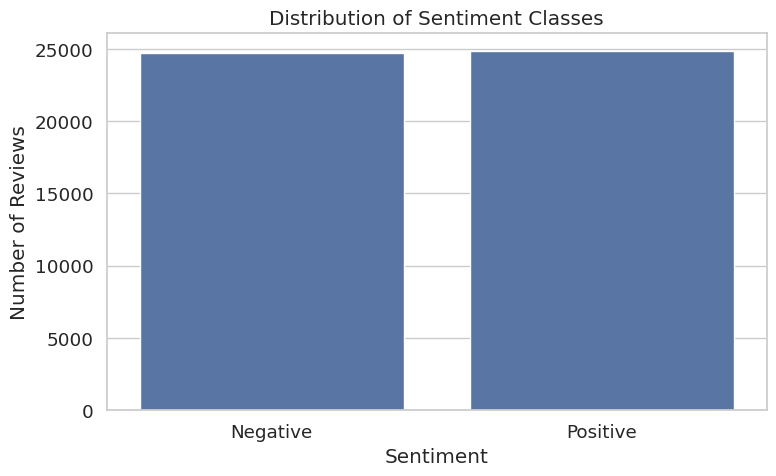

In [166]:
# Sentiment distribution

import matplotlib.pyplot as plt
import seaborn as sns
sentiment_labels = df["sentiment"].map({
    0: "Negative",
    1: "Positive"
})

plt.figure(figsize=(8, 5))

sns.countplot(
    x=sentiment_labels,
    order=["Negative", "Positive"]
)

plt.title("Distribution of Sentiment Classes")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

In [167]:
# Positive and negative count interpretation

sentiment_counts = df['sentiment'].value_counts()

positive_count = sentiment_counts.get(1, 0)
negative_count = sentiment_counts.get(0, 0)

total = len(df)

print(
    f"Positive reviews: {positive_count:,} "
    f"({positive_count/total*100:.2f}%)"
)

print(
    f"Negative reviews: {negative_count:,} "
    f"({negative_count/total*100:.2f}%)"
)

Positive reviews: 24,884 (50.19%)
Negative reviews: 24,698 (49.81%)


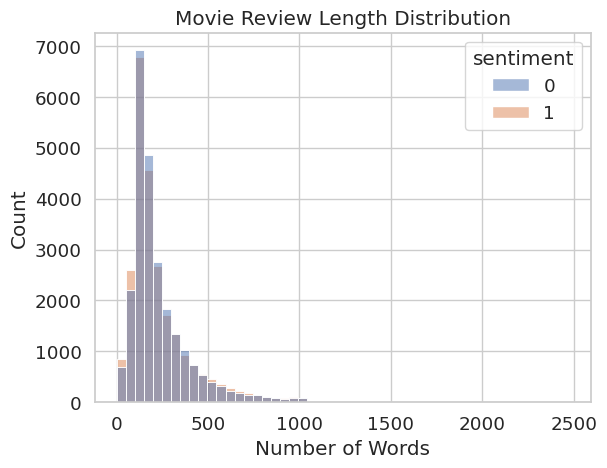

In [168]:
## Review length analysis

df["review_length"] = df["review"].apply(
    lambda x: len(str(x).split())
)

sns.histplot(
    data=df,
    x="review_length",
    hue="sentiment",
    bins=50
)

plt.title("Movie Review Length Distribution")
plt.xlabel("Number of Words")
plt.show()

             count        mean         std   min    25%    50%    75%     max
sentiment                                                                    
0          24698.0  229.596607  165.103430   4.0  128.0  174.0  278.0  1522.0
1          24884.0  233.090620  177.688169  10.0  125.0  172.0  284.0  2470.0


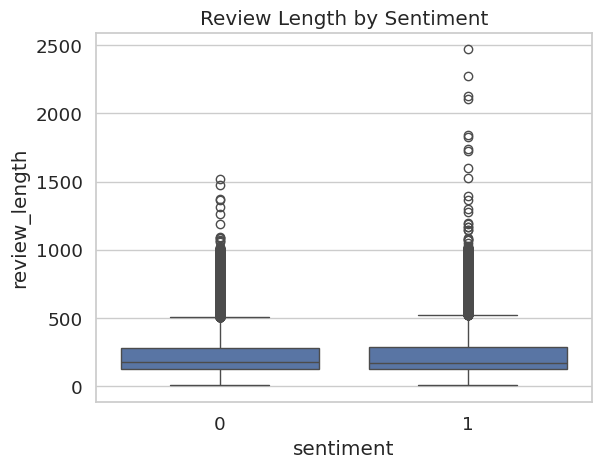

In [169]:
## Compare review lengths
df["review_length"] = df["review"].apply(
    lambda x: len(str(x).split())
)

print(
    df.groupby("sentiment")["review_length"]
    .describe()
)

sns.boxplot(
    data=df,
    x="sentiment",
    y="review_length"
)

plt.title("Review Length by Sentiment")
plt.show()

In [170]:
from wordcloud import WordCloud, STOPWORDS

stop_words = set(STOPWORDS)

stop_words.update([
    "movie",
    "film",
    "one",
    "like",
    "would",
    "really"
])

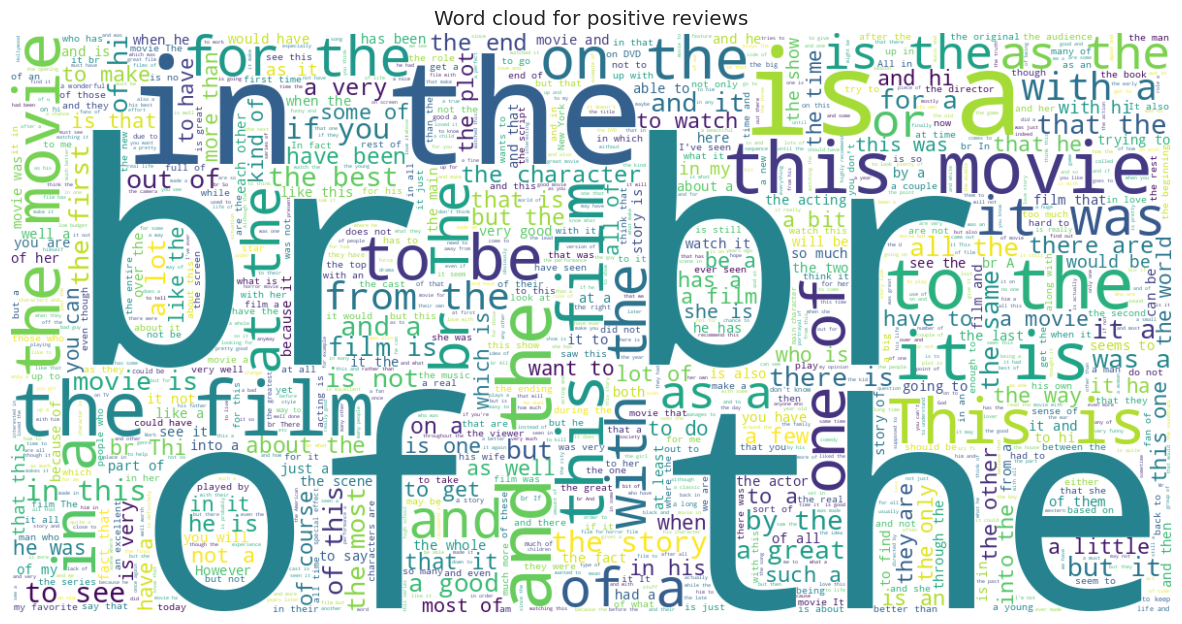

In [171]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

#word cloud for positive reviews
positive_data = df[df.sentiment == 1]['review']
positive_data_string = ' '.join(positive_data)
plt.figure(figsize = (15,8))
wc = WordCloud(
    max_words = 2000,
    width=1200,
    height=600,
    background_color="white",
    stopwords="english"
    ).generate(positive_data_string)

plt.imshow(wc , interpolation = 'bilinear')
plt.axis('off')
plt.title('Word cloud for positive reviews')
plt.show()

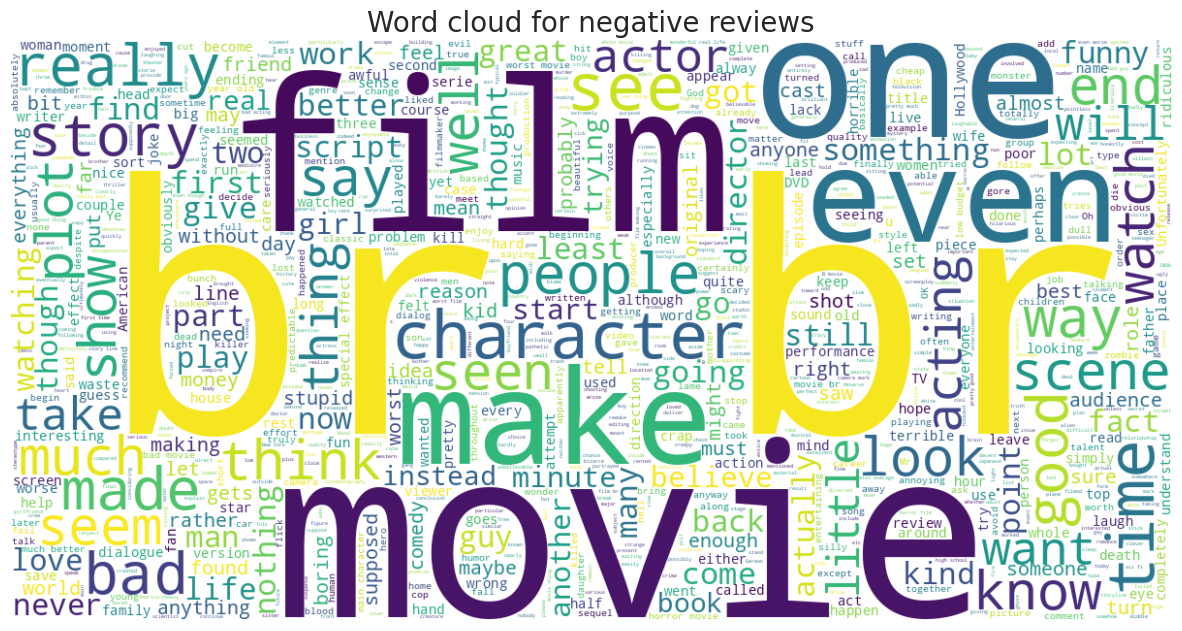

In [172]:
#word cloud for negative reviews
negative_data = df[df.sentiment == 0]['review']
negative_data_string = ' '.join(negative_data)
plt.figure(figsize = (15,8))
wc = WordCloud(
    max_words = 2000,
    width=1200,
    height=600,
    background_color="white").generate(negative_data_string)
plt.imshow(wc , interpolation = 'bilinear')
plt.axis('off')
plt.title('Word cloud for negative reviews',fontsize = 20)
plt.show()

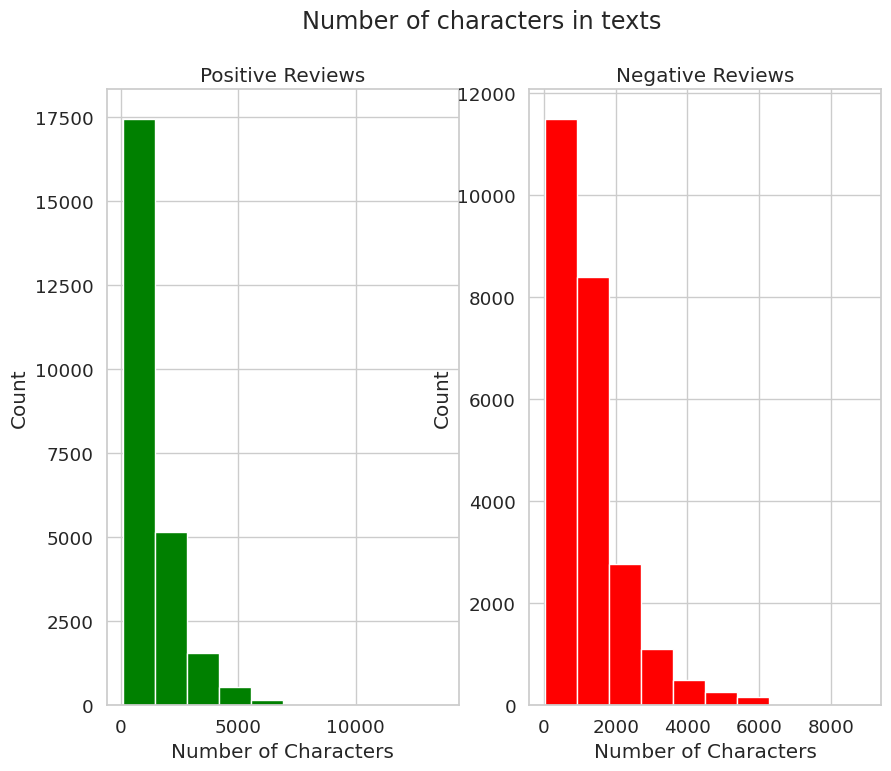

In [173]:
## Number of characters in texts

fig,(ax1,ax2)=plt.subplots(1,2,figsize=(10,8))
text_len=positive_data.str.len()
ax1.hist(text_len,color='green')
ax1.set_title('Positive Reviews')
ax1.set_xlabel('Number of Characters')
ax1.set_ylabel('Count')
text_len=negative_data.str.len()
ax2.hist(text_len,color='red')
ax2.set_title('Negative Reviews')
ax2.set_xlabel('Number of Characters')
ax2.set_ylabel('Count')
fig.suptitle('Number of characters in texts')
plt.show()

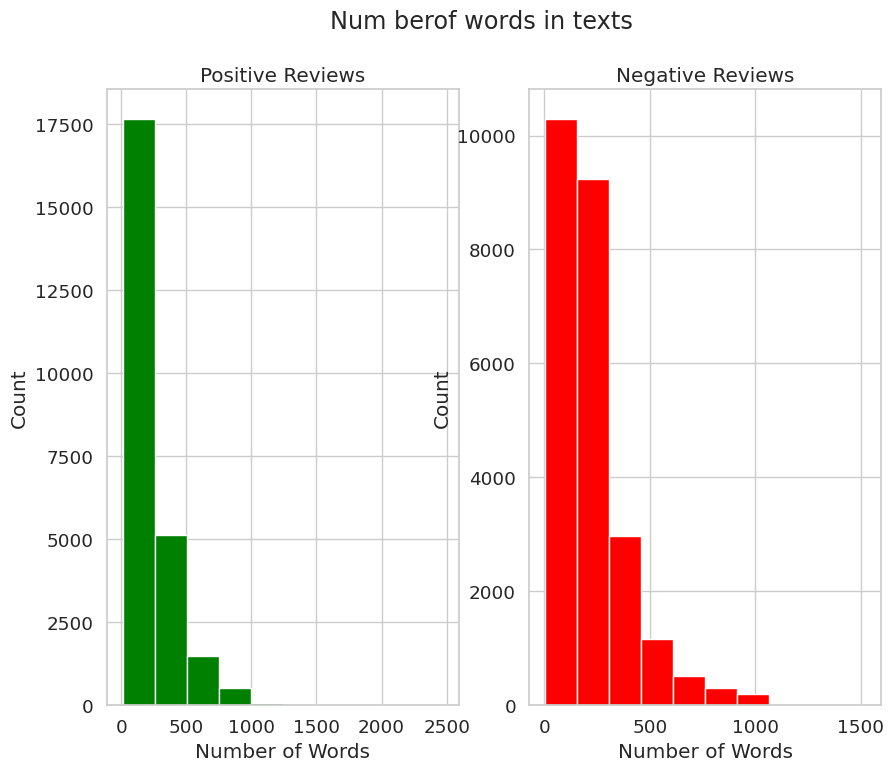

In [174]:
## Num berof words in texts

fig,(ax1,ax2)=plt.subplots(1,2,figsize=(10,8))
text_len=positive_data.str.split().map(lambda x: len(x))
ax1.hist(text_len,color='green')
ax1.set_title('Positive Reviews')
ax1.set_xlabel('Number of Words')
ax1.set_ylabel('Count')
text_len=negative_data.str.split().map(lambda x: len(x))
ax2.hist(text_len,color='red')
ax2.set_title('Negative Reviews')
ax2.set_xlabel('Number of Words')
ax2.set_ylabel('Count')
fig.suptitle('Num berof words in texts')
plt.show()


In [175]:
from collections import Counter

def get_corpus(text):
    words = []
    for i in text:
        for j in i.split():
            words.append(j.strip())
    return words
corpus = get_corpus(df.review)
corpus[:5]

counter = Counter(corpus)
most_common = counter.most_common(10)
most_common = pd.DataFrame(most_common,columns = ['corpus','countv'])
most_common


,corpus,countv
0,the,564474
1,a,304819
2,and,299760
3,of,281597
4,to,259895
5,is,201675
6,in,168738
7,I,131363
8,that,125878
9,this,112817


In [176]:
most_common = most_common.sort_values('countv')

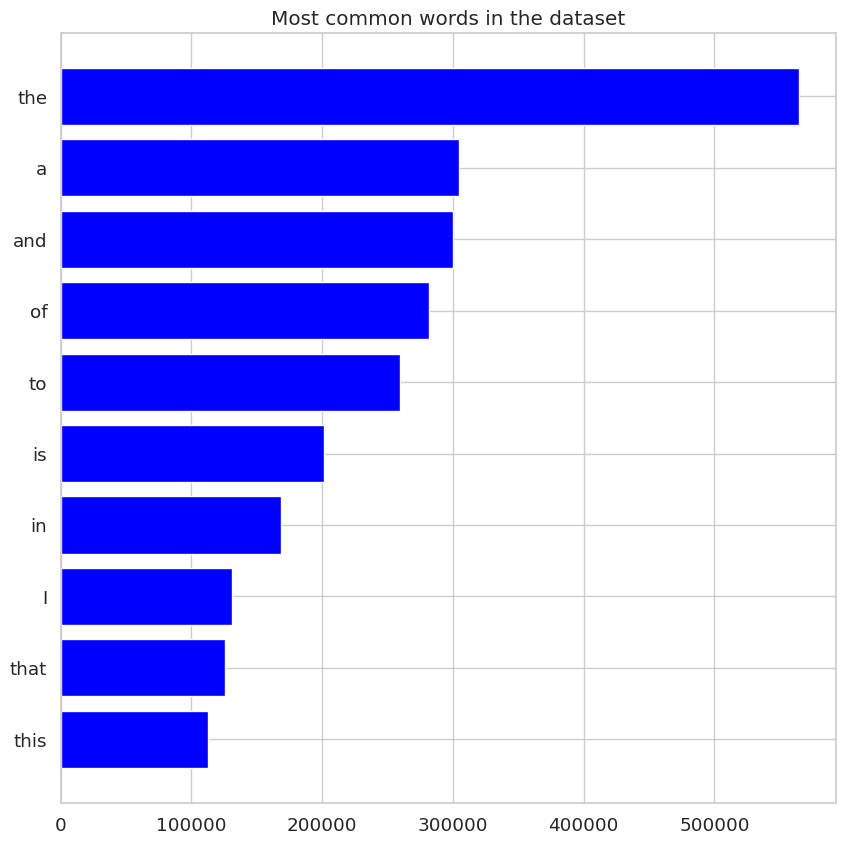

In [177]:
plt.figure(figsize =(10,10))
plt.yticks(range(len(most_common)), list(most_common.corpus))
plt.barh(range(len(most_common)), list(most_common.countv),align='center',color = 'blue')
plt.title('Most common words in the dataset')
plt.show()


In [178]:
## Remove stopwords and count meaningful words
import re
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

In [179]:
# Convert stopwords into a set
stop_words = set(ENGLISH_STOP_WORDS)

# Preserve important negation words
negation_words = {'not', 'no', 'nor', 'never'}
stop_words = stop_words - negation_words


# Function to extract meaningful words
def get_most_common_words(reviews, stop_words, n=15):

    words = []

    for review in reviews:
        # Convert text to lowercase
        review = str(review).lower()

        # Extract words
        tokens = re.findall(r"\b[a-zA-Z]+\b", review)

# Remove stopwords and very short words
        meaningful_words = [
            word for word in tokens
            if word not in stop_words and len(word) > 2
        ]

        words.extend(meaningful_words)

    return Counter(words).most_common(n)

In [180]:
## Analyse positive and negative reviews separately

In [181]:
# Separate positive and negative reviews
positive_reviews = df[df['sentiment'] == 1]['review']
negative_reviews = df[df['sentiment'] == 0]['review']

# Get the 15 most frequent meaningful words
positive_words = get_most_common_words(positive_reviews, stop_words, 15)
negative_words = get_most_common_words(negative_reviews, stop_words, 15)

# Convert results into DataFrames
positive_df = pd.DataFrame(positive_words, columns=['Word', 'Frequency'])
negative_df = pd.DataFrame(negative_words, columns=['Word', 'Frequency'])

print("Top 15 Meaningful Words in Positive Reviews")
display(positive_df)

print("Top 15 Meaningful Words in Negative Reviews")
display(negative_df)

Top 15 Meaningful Words in Positive Reviews


,Word,Frequency
0,film,41970
1,movie,37660
2,not,28204
3,like,17651
4,good,14966
5,just,14057
6,story,12898
7,great,12889
8,time,12701
9,really,10706


Top 15 Meaningful Words in Negative Reviews


,Word,Frequency
0,movie,49616
1,film,37178
2,not,32067
3,like,22192
4,just,20870
5,good,14581
6,bad,14563
7,really,12217
8,time,12205
9,don,10502


In [182]:
## Visualise the results

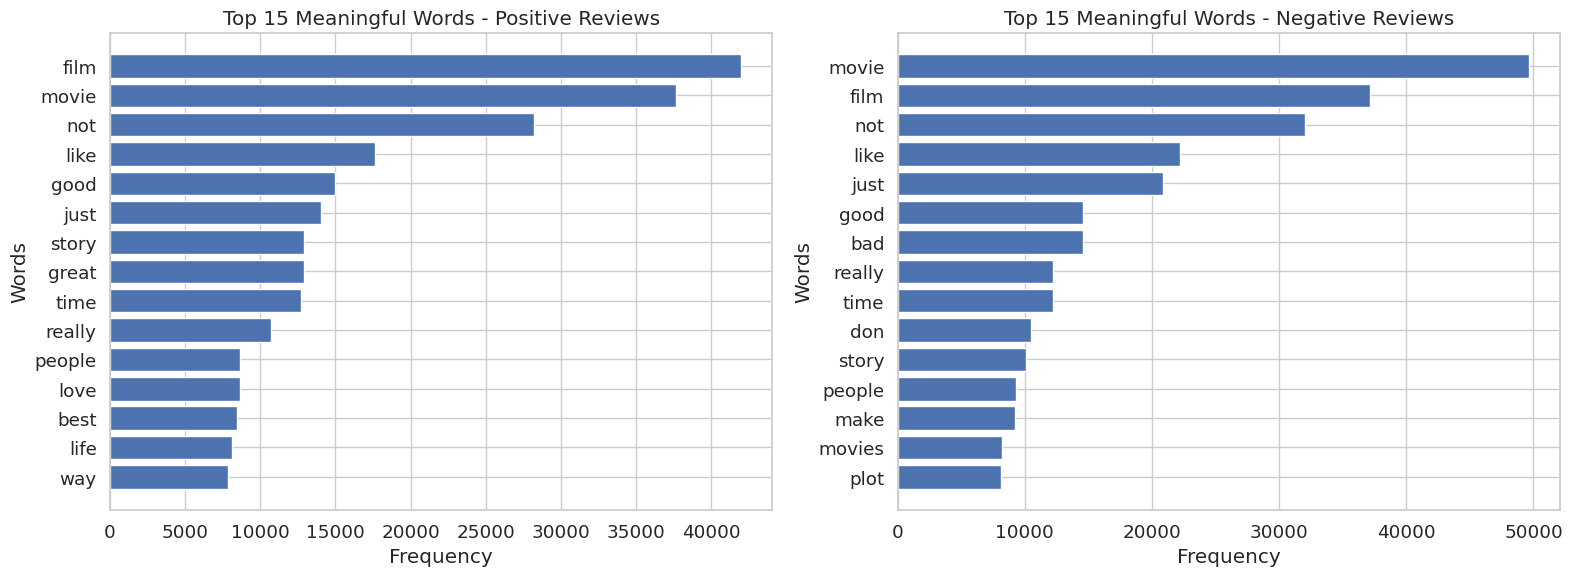

In [183]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Positive reviews
axes[0].barh(
    positive_df['Word'][::-1],
    positive_df['Frequency'][::-1]
)
axes[0].set_title('Top 15 Meaningful Words - Positive Reviews')
axes[0].set_xlabel('Frequency')
axes[0].set_ylabel('Words')

# Negative reviews
axes[1].barh(
    negative_df['Word'][::-1],
    negative_df['Frequency'][::-1]
)
axes[1].set_title('Top 15 Meaningful Words - Negative Reviews')
axes[1].set_xlabel('Frequency')
axes[1].set_ylabel('Words')

plt.tight_layout()
plt.show()